In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from cogformer.simulator import ModelFamily
from cogformer.simulator.benchmarks import DDM
from cogformer.simulator.benchmarks.ddms.ddm_priors import ddm_priors
from cogformer.simulator.benchmarks.ddms.ddm_link_fun import ddm_link_fun

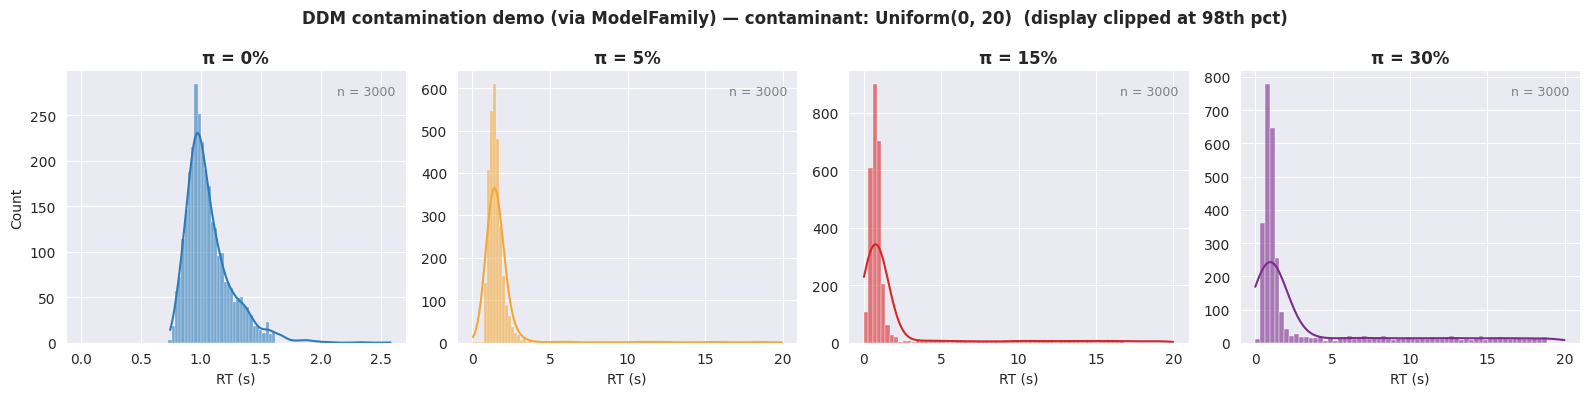

In [6]:
np.random.seed(42)

NUM_OBS   = 3000
PI_LEVELS = [0.0, 0.05, 0.15, 0.30]

# --- Simulate at each contamination level via ModelFamily ---
results = {}
for pi in PI_LEVELS:
    ddm = DDM(pi=pi)
    family = ModelFamily(model=ddm, prior_fun=ddm_priors(), name=f"DDM-pi{pi}")
    out = family.sample(num_obs=NUM_OBS, link_fun=ddm_link_fun())
    rts     = out["sim_trials"]["rts"].squeeze()
    choices = out["sim_trials"]["choices"].squeeze()
    valid   = rts > 0
    results[pi] = {"rts": rts[valid], "choices": choices[valid]}

# --- Plot ---
palette = ["#2b7bb9", "#f4a736", "#d62728", "#7b2d8b"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)

for ax, pi, color in zip(axes, PI_LEVELS, palette):
    rts = results[pi]["rts"]
    clip_val = np.percentile(rts, 98)
    sns.histplot(
        rts, bins=60, kde=True,
        color=color, alpha=0.6,
        binrange=(0, clip_val),
        ax=ax,
    )
    ax.set_title(f"π = {pi:.0%}", fontsize=12, fontweight="bold")
    ax.set_xlabel("RT (s)", fontsize=10)
    ax.set_ylabel("Count" if ax is axes[0] else "", fontsize=10)
    ax.annotate(
        f"n = {len(rts)}",
        xy=(0.97, 0.95), xycoords="axes fraction",
        ha="right", va="top", fontsize=9, color="gray",
    )
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "DDM contamination demo (via ModelFamily) — contaminant: Uniform(0, 20)  (display clipped at 98th pct)",
    fontsize=12, fontweight="bold",
)
plt.tight_layout()